# telco-anomaly-rca: walkthrough

**All data is synthetic** (seeded generator in `src/anomaly/data.py`); it is not data from Airtel or any other operator.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / 'src'))
from IPython.display import Image, Markdown, display

In [2]:
from anomaly.data import generate
generate().head()

,date,region,channel,agent,gross_adds,recharges,agent_float
0,2024-01-01,Nairobi,Agent,AG-N-01,377,957553.0,347334.0
1,2024-01-02,Nairobi,Agent,AG-N-01,325,989343.0,375299.0
2,2024-01-03,Nairobi,Agent,AG-N-01,323,920271.0,359892.0
3,2024-01-04,Nairobi,Agent,AG-N-01,272,858096.0,359492.0
4,2024-01-05,Nairobi,Agent,AG-N-01,306,930840.0,385875.0


## Run the full analysis pipeline

In [3]:
from anomaly import run
_ = run.main()

# Results summary (SYNTHETIC DATA)

## Detection vs injected ground truth

| Injected date | KPI | National z | Segment scan flagged | Drill-down path (share of deviation) |
|---|---|---|---|---|
| 2025-03-14 | gross_adds | -0.7 (hidden) | Coast/Agent (z=-34), Nairobi/Agent (z=9) | Coast (100%) → Agent (100%) → AG-C-02 (70%) |
| 2025-06-02 | recharges | 1.6 (hidden) | Central/Agent (z=9), Nairobi/App (z=-26) | Nairobi (100%) → App (100%) → - (0%) |
| 2025-08-21 | agent_float | -1.4 (hidden) | Western/Agent (z=-12) | Western (84%) → Agent (0%) → AG-W-03 (100%) |
| 2025-11-07 | gross_adds | 0.4 (hidden) | Nairobi/Agent (z=-8), Rift Valley/Retail Shop (z=51), Rift Valley/USSD Self-serve (z=-8) | Rift Valley (100%) → Retail Shop (100%) → - (0%) |

Segment scan caught 4/4 injected incidents; other segment-days flagged: 299 of 57,456 (0.52%) for analyst review.

IsolationForest on the day x segment |z| matrix flagged 5 days; 1/4 injected dates among them.

## Forecast: 91-day holdout, nation

## Figures

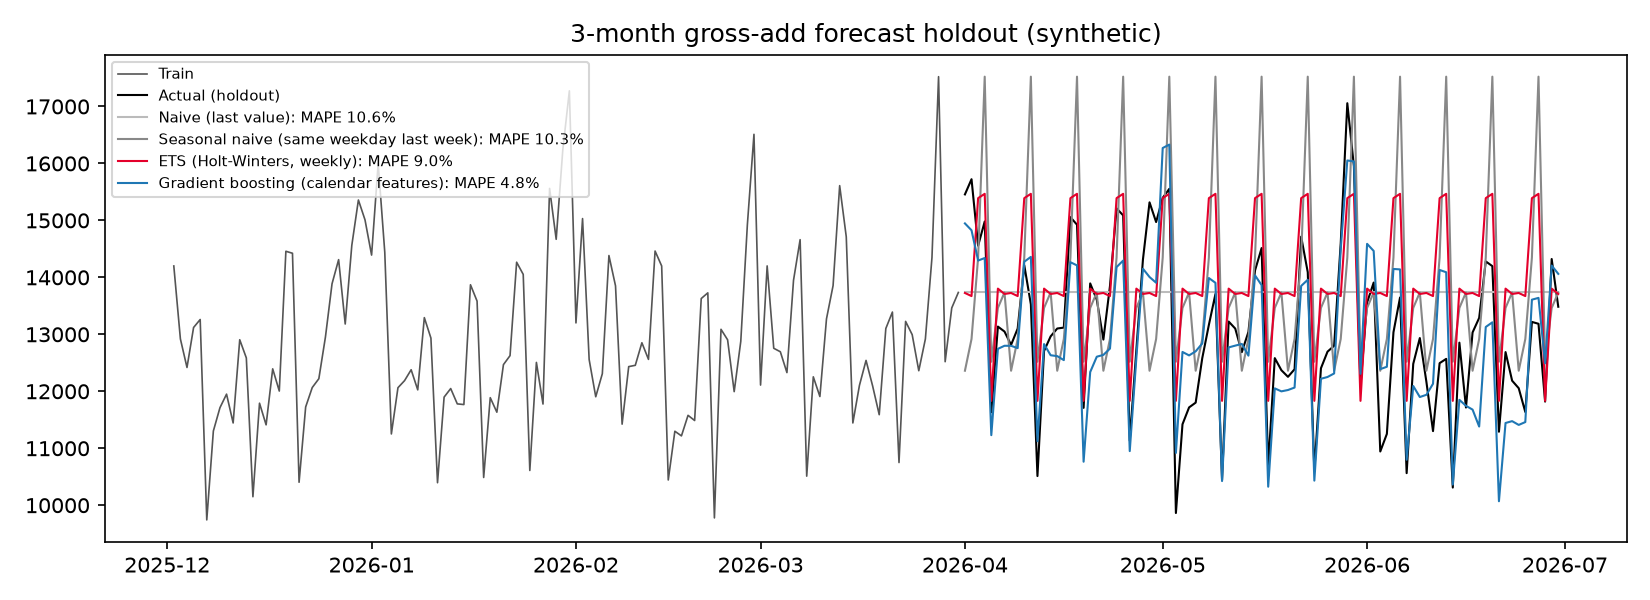

In [4]:
display(Image('../reports/figures/forecast_holdout.png'))

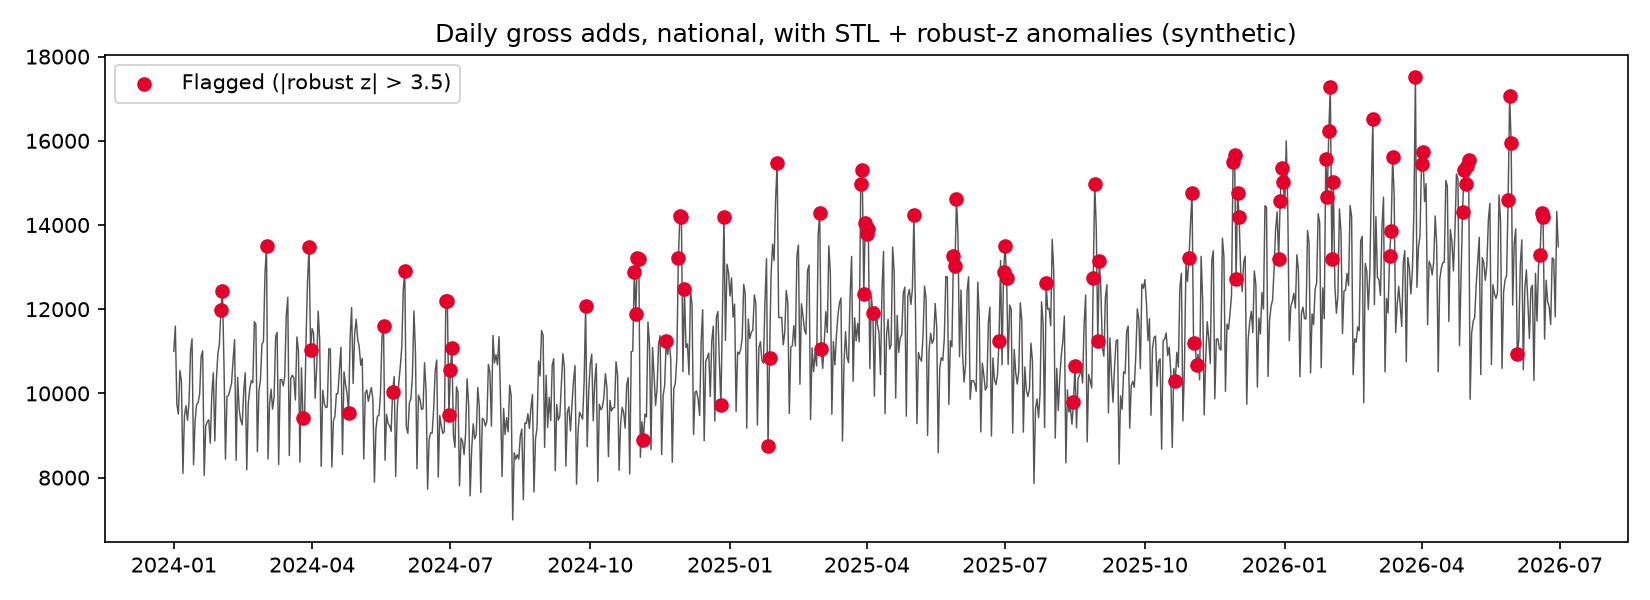

In [5]:
display(Image('../reports/figures/gross_adds_anomalies.png'))

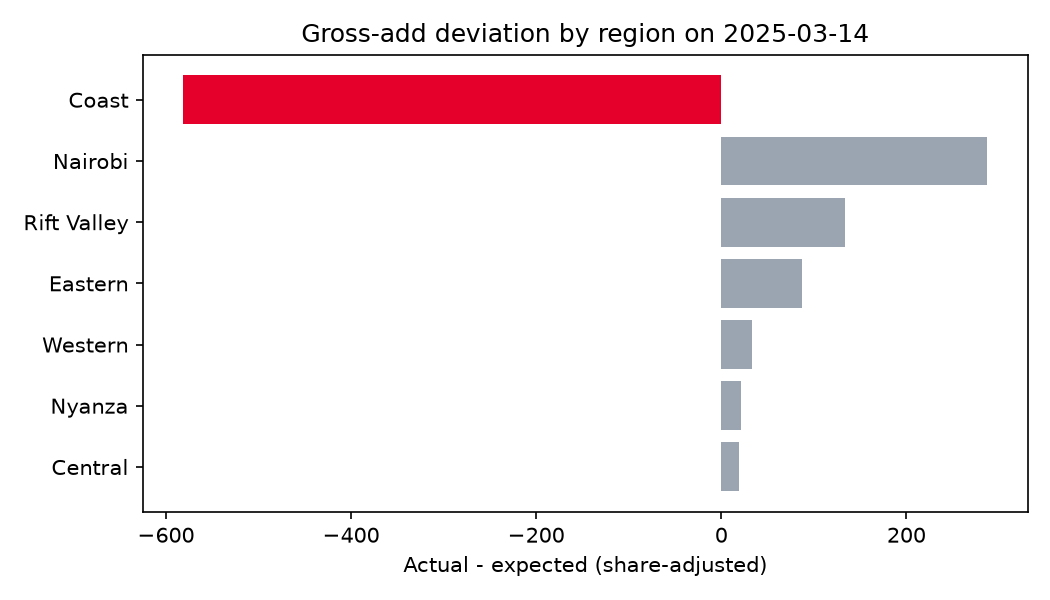

In [6]:
display(Image('../reports/figures/rca_contribution.png'))